# Pretrained encoders and velocity consistency

This is the experiment of our project proposal. Cluster records each surface at five speeds (20 to 60 mm/s). The same
surface sounds different at each speed. Our idea: during training, give the model two recordings of the same surface
at two speeds, and ask it to give the **same answer** for both (a "consistency penalty").

Does it help on new surfaces? And on new surfaces at a speed never seen in training?

We use BEATs, a pretrained audio model, in two ways:

1. **frozen**: BEATs (and CLAP) only turn each window into a vector, a logistic regression does the rest;
2. **fine-tuned**: we train BEATs and a small head on Cluster, with or without the consistency penalty.

All tests are on Cluster, with surfaces never seen in training. Slow part: about 4 hours on an 8 GB GPU. The tables are
saved in `results/` and the training starts again where it stopped.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchaudio
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from torch import nn
from transformers import ClapModel, ClapProcessor

sys.path.insert(0, "models/beats")
from BEATs import BEATs, BEATsConfig

FAMILIES = ["wood", "metal", "textile", "polymer"]
device = "cuda"

## The data

From `data.ipynb`: windows of 0.5 s of each Cluster recording, the sound at 16 kHz and the vibration at 8 kHz (main
axis), all at the same loudness. One row of `info` per recording.

In [2]:
saved = np.load("cache/spectra.npz", allow_pickle=True)
info = pd.DataFrame({c: saved[c] for c in ["dataset", "surface", "family", "velocity", "direction", "force", "repeat"]})
windows = np.load("cache/windows_two_setups.npz")
owner = windows["recording"]
has_windows = np.bincount(owner, minlength=len(info)) > 0
cluster = (info.dataset == "cluster").to_numpy() & has_windows

# the vibration goes to 16 kHz, the rate BEATs expects
vibration = torch.cat([torchaudio.functional.resample(torch.tensor(windows["vibration"][i : i + 4096].astype(np.float32)), 8000, 16000)
                       for i in range(0, len(owner), 4096)]).half()
signals = {"sound": torch.tensor(windows["sound"]), "vibration": vibration}

# five groups of Cluster surfaces, the same share of each family in each group
surfaces = info[cluster][["surface", "family"]].drop_duplicates().reset_index(drop=True)
fold_of = {}
for k, (_, test) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(surfaces.surface, surfaces.family)):
    fold_of.update({s: k for s in surfaces.surface[test]})
fold = info.surface.map(fold_of).fillna(-1).to_numpy()
print(cluster.sum(), "Cluster recordings,", len(owner), "windows")

11520 Cluster recordings, 51738 windows


## How we score

Balanced accuracy over the recordings (one answer per recording: the mean of its windows), with a 95 % interval
from drawing the surfaces again 2000 times. We also give precision, recall and F1 per family, and the confusion
matrix.

In [3]:
def balanced_with_interval(truth, answers, surface):
    table = pd.DataFrame({"truth": truth, "answer": answers, "surface": surface})
    per_surface = {s: confusion_matrix(g.truth, g.answer, labels=FAMILIES) for s, g in table.groupby("surface")}
    family_of_surface = table.groupby("surface").truth.first()
    recall = lambda m: np.mean(np.diag(m) / np.maximum(m.sum(axis=1), 1))
    rng = np.random.default_rng(42)
    draws = []
    for _ in range(2000):
        m = np.zeros((4, 4))
        for f in FAMILIES:
            names = family_of_surface.index[family_of_surface == f]
            for s in rng.choice(names, len(names)):
                m += per_surface[s]
        draws.append(recall(m))
    return recall(sum(per_surface.values())), *np.percentile(draws, [2.5, 97.5])


def per_family(truth, answers):
    p, r, f, n = precision_recall_fscore_support(truth, answers, labels=FAMILIES, zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "F1": f, "recordings": n}, index=FAMILIES)

## 1. Frozen encoders + logistic regression

One vector per window from BEATs (768 numbers) and from CLAP (512), then the mean per recording. Five folds of
Cluster surfaces.

In [4]:
checkpoint = torch.load("models/beats/BEATs_iter3_plus_AS2M.pt", map_location="cpu", weights_only=True)


def load_beats():
    model = BEATs(BEATsConfig(checkpoint["cfg"]))
    model.load_state_dict(checkpoint["model"])
    # the filter bank of BEATs overflows in half precision: always compute it in full precision
    preprocess = model.preprocess

    def preprocess_in_float32(source, **kwargs):
        with torch.autocast("cuda", enabled=False):
            return preprocess(source.float(), **kwargs)

    model.preprocess = preprocess_in_float32
    return model.to(device)


def beats_vector(model, x):
    return model.extract_features(x.float() * 0.1)[0].mean(dim=1)


clap = ClapModel.from_pretrained("laion/clap-htsat-unfused").to(device).eval()
extractor = ClapProcessor.from_pretrained("laion/clap-htsat-unfused").feature_extractor
mel_filters = torch.tensor(extractor.mel_filters_slaney, dtype=torch.float32, device=device)
hann = torch.hann_window(1024, device=device)


def clap_vector(x):
    with torch.autocast("cuda", enabled=False):
        mel = clap_input(x)
    longer = torch.zeros(len(x), 1, dtype=torch.bool, device=device)
    return clap.get_audio_features(input_features=mel, is_longer=longer).pooler_output


def clap_input(x):
    x = torchaudio.functional.resample(x.float(), 16000, 48000).repeat(1, 20) * 0.1
    power = torch.stft(x, 1024, 480, window=hann, return_complex=True).abs() ** 2
    return (10 * torch.log10(torch.clamp(mel_filters.T @ power, min=1e-10))).transpose(1, 2)[:, None]


def per_recording(embed, name):
    file = Path(f"cache/frozen_{name}.npy")
    if not file.exists():
        rows = np.flatnonzero(cluster[owner])
        out = []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for i in range(0, len(rows), 128):
                out.append(embed(signals[name.split("_")[1]][rows[i : i + 128]].to(device)).float().cpu().numpy())
        means = pd.DataFrame(np.concatenate(out)).groupby(owner[rows]).mean()
        np.save(file, means.reindex(range(len(info))).to_numpy(np.float32))
    return np.load(file)


beats = load_beats().eval()
frozen = {}
for signal_name in ["sound", "vibration"]:
    frozen[f"BEATs {signal_name}"] = per_recording(lambda x: beats_vector(beats, x), f"beats_{signal_name}")
    frozen[f"CLAP {signal_name}"] = per_recording(clap_vector, f"clap_{signal_name}")
del beats, clap
torch.cuda.empty_cache()

In [5]:
# about an hour on a CPU: the answers are kept in results/ and read back the next time
answers_file = Path("results/velocity_frozen_answers.csv")
rows, frozen_answers = [], {}
saved_answers = pd.read_csv(answers_file, index_col=0) if answers_file.exists() else pd.DataFrame()
for encoder in ["BEATs", "CLAP"]:
    for name, parts in [("sound", ["sound"]), ("vibration", ["vibration"]), ("sound + vibration", ["sound", "vibration"])]:
        x = np.hstack([frozen[f"{encoder} {p}"] for p in parts])
        if f"{encoder} frozen, {name}" in saved_answers:
            answers = saved_answers[f"{encoder} frozen, {name}"].reindex(np.flatnonzero(cluster))
        else:
            answers = pd.Series(index=np.flatnonzero(cluster), dtype=object)
        for k in range(5 if answers.isna().any() else 0):
            train, test = cluster & (fold != k), cluster & (fold == k)
            weight = 1 / info[train].groupby("family").family.transform("size").to_numpy()
            scaler = StandardScaler().fit(x[train])
            model = LogisticRegression(max_iter=3000).fit(scaler.transform(x[train]), info.family[train], sample_weight=weight / weight.mean())
            answers[np.flatnonzero(test)] = model.predict(scaler.transform(x[test]))
        score, low, high = balanced_with_interval(info.family[cluster], answers.to_numpy(), info.surface[cluster])
        rows.append({"model": f"{encoder} frozen + logistic", "signal": name, "score": score, "low": low, "high": high})
        frozen_answers[f"{encoder} frozen, {name}"] = answers
pd.DataFrame(frozen_answers).to_csv(answers_file)
frozen_scores = pd.DataFrame(rows)
frozen_scores.to_csv("results/velocity_frozen_encoders.csv", index=False)
frozen_scores.round(2)

,model,signal,score,low,high
0,BEATs frozen + logistic,sound,0.72,0.66,0.78
1,BEATs frozen + logistic,vibration,0.63,0.58,0.68
2,BEATs frozen + logistic,sound + vibration,0.74,0.68,0.80
3,CLAP frozen + logistic,sound,0.67,0.62,0.72
4,CLAP frozen + logistic,vibration,0.58,0.53,0.63
5,CLAP frozen + logistic,sound + vibration,0.69,0.63,0.74


## 2. Fine-tuning BEATs, with and without the consistency penalty

BEATs on the sound and on the vibration (the same encoder for both), then a small head. Each batch has 32 **pairs**
(the same surface, direction, force and repeat, two different speeds) and 32 other training recordings, one random
window of each.

Loss = cross-entropy (every family weighs the same) + λ × the disagreement between the two answers of each pair
(symmetric KL divergence). λ = 0 is the plain model, λ = 1 the model of our proposal. Both see exactly the same
batches.

Two tests, five folds each:

- **new surfaces**: all speeds in training;
- **new surfaces at an unseen speed**: no recording at 60 mm/s in training, test on 60 mm/s only.

In [6]:
class FineTuned(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = load_beats()
        self.head = nn.Sequential(nn.Dropout(0.1), nn.Linear(2 * 768, 4))

    def forward(self, windows):
        parts = [beats_vector(self.encoder, signals[s][windows].to(device)) for s in ["sound", "vibration"]]
        return self.head(torch.cat(parts, dim=1))


first = np.searchsorted(owner, np.arange(len(info)))
count = np.bincount(owner, minlength=len(info))
family_number = info.family.map(FAMILIES.index).to_numpy()


def one_window(recordings, rng):
    return first[recordings] + rng.integers(0, count[recordings])


def disagreement(a, b):
    la, lb = a.log_softmax(dim=1), b.log_softmax(dim=1)
    return 0.5 * ((la.exp() * (la - lb)).sum(1) + (lb.exp() * (lb - la)).sum(1)).mean()


def train(training, penalty, seed, steps=1500):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = FineTuned().to(device)
    optimizer = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": 2e-5},
                                   {"params": model.head.parameters(), "lr": 1e-3}], weight_decay=0.01)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[2e-5, 1e-3], total_steps=steps, pct_start=0.1)
    scaler = torch.amp.GradScaler()

    # pairs: same surface, direction, force and repeat, two different speeds
    table = info[training].reset_index()
    pairs = table.merge(table, on=["surface", "direction", "force", "repeat"], suffixes=("_a", "_b"))
    pairs = pairs[pairs.velocity_a < pairs.velocity_b][["index_a", "index_b"]].to_numpy()
    others = np.flatnonzero(training)
    weight = np.zeros(len(info))
    weight[training] = 1 / info[training].groupby("family").family.transform("size").to_numpy()

    model.train()
    for _ in range(steps):
        chosen = pairs[rng.integers(0, len(pairs), 32)]
        recordings = np.concatenate([chosen[:, 0], chosen[:, 1], rng.choice(others, 32)])
        w = torch.tensor(weight[recordings], device=device, dtype=torch.float32)
        optimizer.zero_grad()
        for half in [np.r_[0:16, 32:48, 64:80], np.r_[16:32, 48:64, 80:96]]:  # two halves, to fit in memory
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(one_window(recordings[half], rng)).float()
            truth = torch.tensor(family_number[recordings[half]], device=device)
            loss = (nn.functional.cross_entropy(logits, truth, reduction="none") * w[half]).sum() / w.sum()
            if penalty:
                loss = loss + penalty * disagreement(logits[:16], logits[16:32]) / 2
            scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        schedule.step()
    return model.eval()


def answers_of(model, recordings):
    rows = np.flatnonzero(np.isin(owner, recordings))
    chances = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for i in range(0, len(rows), 64):
            chances.append(model(rows[i : i + 64]).float().softmax(dim=1).cpu().numpy())
    per_recording = pd.DataFrame(np.concatenate(chances), columns=FAMILIES).groupby(owner[rows]).mean()
    return per_recording.idxmax(axis=1)

In [7]:
file = Path("results/velocity_consistency_answers.csv")
done = pd.read_csv(file) if file.exists() else pd.DataFrame(columns=["test", "penalty", "fold"])
slow = (info.velocity != 60).to_numpy()

for k in range(5):
    tests = {
        "new surfaces": (cluster & (fold != k), cluster & (fold == k)),
        "new surfaces at an unseen speed (60 mm/s)": (cluster & (fold != k) & slow, cluster & (fold == k) & ~slow),
    }
    for test_name, (training, tested) in tests.items():
        for penalty in [0.0, 1.0]:
            if ((done.test == test_name) & (done.penalty == penalty) & (done.fold == k)).any():
                continue
            model = train(training, penalty, seed=k)
            answers = answers_of(model, np.flatnonzero(tested))
            rows = pd.DataFrame({"test": test_name, "penalty": penalty, "fold": k, "recording": answers.index, "answer": answers.to_numpy()})
            rows.to_csv(file, mode="a", header=not file.exists(), index=False)
            del model
            torch.cuda.empty_cache()
            print(test_name, "| fold", k, "| penalty", penalty, "done", flush=True)

new surfaces at an unseen speed (60 mm/s) | fold 4 | penalty 0.0 done


new surfaces at an unseen speed (60 mm/s) | fold 4 | penalty 1.0 done


## Results

In [8]:
answers = pd.read_csv(file)
rows = []
for (test_name, penalty), group in answers.groupby(["test", "penalty"]):
    truth = info.family[group.recording].to_numpy()
    score, low, high = balanced_with_interval(truth, group.answer.to_numpy(), info.surface[group.recording].to_numpy())
    rows.append({"test": test_name, "model": "BEATs fine-tuned" + (" + consistency" if penalty else ""), "score": score, "low": low, "high": high})
fine_tuned = pd.DataFrame(rows)
fine_tuned.to_csv("results/velocity_consistency_scores.csv", index=False)
fine_tuned.round(2)

,test,model,score,low,high
0,new surfaces,BEATs fine-tuned,0.75,0.68,0.82
1,new surfaces,BEATs fine-tuned + consistency,0.75,0.68,0.82
2,new surfaces at an unseen speed (60 mm/s),BEATs fine-tuned,0.68,0.62,0.74
3,new surfaces at an unseen speed (60 mm/s),BEATs fine-tuned + consistency,0.68,0.62,0.74


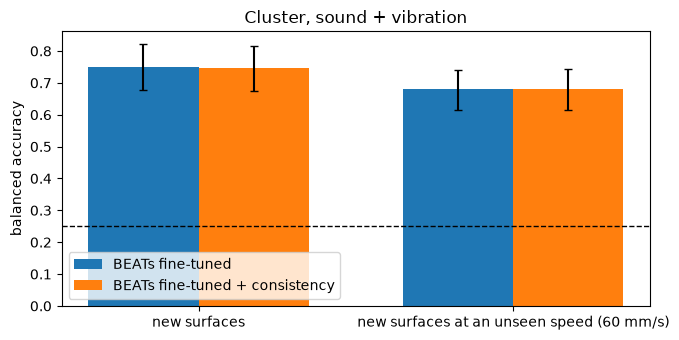

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, (model_name, group) in enumerate(fine_tuned.groupby("model")):
    x = np.arange(len(group)) + (i - 0.5) * 0.35
    ax.bar(x, group.score, 0.35, label=model_name)
    ax.errorbar(x, group.score, [group.score - group.low, group.high - group.score], fmt="none", color="black", capsize=3)
ax.set_xticks(range(len(group)), group.test)
ax.axhline(0.25, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("balanced accuracy")
ax.set_title("Cluster, sound + vibration")
ax.legend()
plt.tight_layout()
plt.savefig("results/velocity_consistency.png", dpi=120)

## Per family, for the best models

BEATs fine-tuned, new surfaces of Cluster
         precision  recall    F1  recordings
wood          0.94    0.99  0.96        5600
metal         0.67    0.62  0.65        1440
textile       0.88    0.95  0.92        2880
polymer       0.59    0.44  0.50        1600


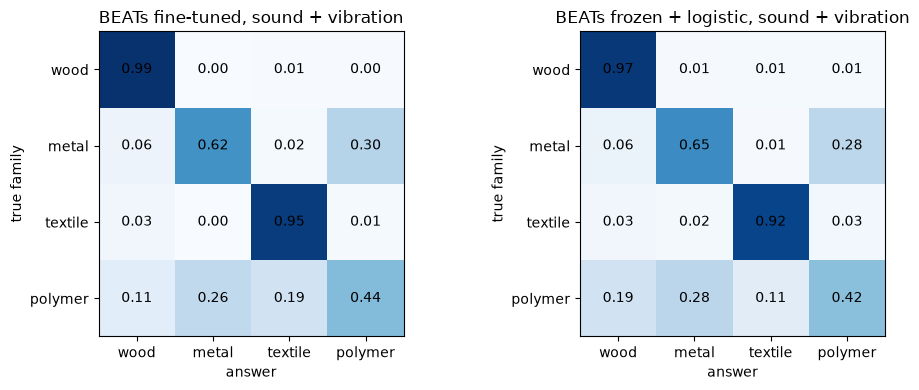

In [10]:
best = answers[(answers.test == "new surfaces") & (answers.penalty == 0)]
truth = info.family[best.recording].to_numpy()
print("BEATs fine-tuned, new surfaces of Cluster")
print(per_family(truth, best.answer.to_numpy()).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pairs = [("BEATs fine-tuned", truth, best.answer.to_numpy()),
         ("BEATs frozen + logistic", info.family[frozen_answers["BEATs frozen, sound + vibration"].index].to_numpy(),
          frozen_answers["BEATs frozen, sound + vibration"].to_numpy())]
for ax, (title, t, a) in zip(axes, pairs):
    m = confusion_matrix(t, a, labels=FAMILIES, normalize="true")
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center")
    ax.set_xticks(range(4), FAMILIES)
    ax.set_yticks(range(4), FAMILIES)
    ax.set_xlabel("answer")
    ax.set_ylabel("true family")
    ax.set_title(title + ", sound + vibration")
plt.tight_layout()
plt.savefig("results/velocity_confusion.png", dpi=120)

## What we see

- Frozen BEATs with a logistic regression already reaches 0.74 on new surfaces of Cluster (sound and vibration
  together), CLAP 0.69. Sound alone does better than vibration alone.
- Fine-tuning BEATs does about as well: 0.75.
- The consistency penalty of our proposal changes nothing: 0.75 with or without it on new surfaces, 0.68 with or
  without it on new surfaces at an unseen speed.
- An unseen speed costs about 0.07, much less than an unseen setup (see `new_setup.ipynb`).
- Wood and textile are easy (F1 0.96 and 0.92), polymer is the hard family (F1 0.50).

So speed was not the main problem: the setup is. That is why the rest of the project studies the change of setup.